In [2]:
# pierwsza wartosc to jak czesto to slowa pojawilo sie w ogloszeniu o prace, a druga to jak czesto w resume
data = [ ("big data", 100, 15), ("Hadoop", 95, 25), ("Python", 75, 50),
         ("R", 50, 40), ("machine learning", 80, 20), ("statistics", 20, 60),
         ("data science", 60, 70), ("analytics", 90, 3),
         ("team player", 85, 85), ("dynamic", 2, 90), ("synergies", 70, 0),
         ("actionable insights", 40, 30), ("think out of the box", 45, 10),
         ("self-starter", 30, 50), ("customer focus", 65, 15),
         ("thought leadership", 35, 35)]

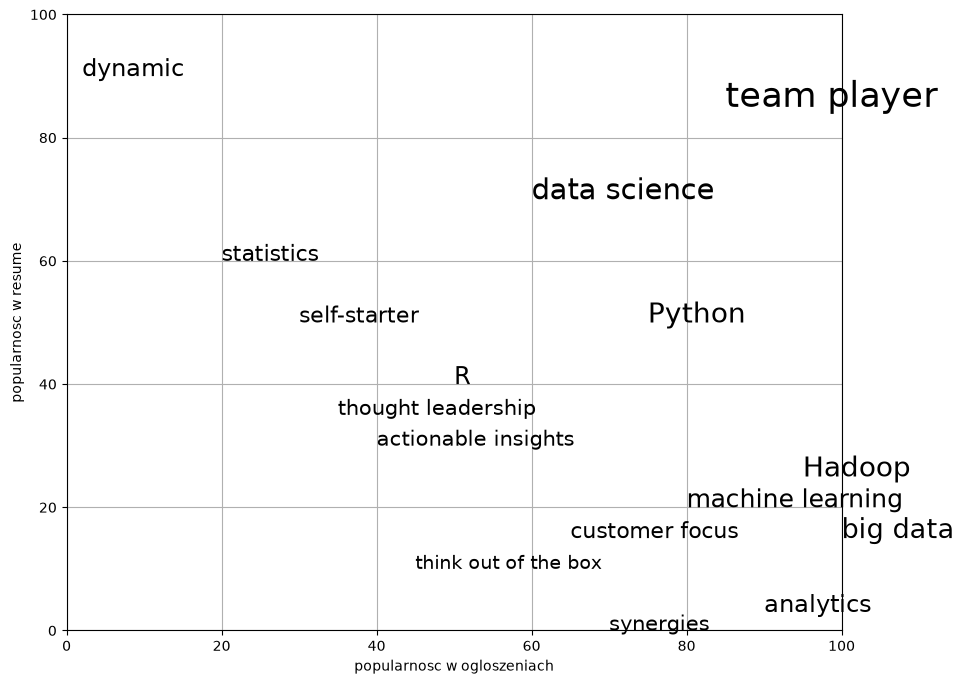

In [3]:
from matplotlib import pyplot as plt

def text_size(total: int) -> float:
    """wielkosc napisu w zaleznosci od sumy jego wystepowania"""
    return (20 / 200) * total + 8

assert text_size(0) == 8 and text_size(200) == 28

plt.figure(figsize=(10, 8))

for word, f_1, f_2 in data:
    plt.text(
        f_1, f_2, 
        word, 
        size=text_size(f_1 + f_2),
    )

plt.xlim(0, 100)
plt.ylim(0, 100)
plt.xlabel("popularnosc w ogloszeniach")
plt.ylabel("popularnosc w resume")
plt.grid(True)

plt.show()

In [4]:
import re
from bs4 import BeautifulSoup
import requests

url = "https://www.oreilly.com/ideas/what-is-data-science"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
}

resp = requests.get(url, headers=headers)
resp.raise_for_status()

soup = BeautifulSoup(resp.text, "html.parser")

def fix_unicode(text: str) -> str:
    return text.replace("\u2019", "'")

# Szukamy kontenera artykułu — bezpieczny fallback na znacznik <article> lub bezpośrednio <body>
content =  soup.body

regex = r"[\w']+|[.]"
document = []

if content:
    for paragraph in content.find_all("p"):
        words = re.findall(regex, fix_unicode(paragraph.text))
        document.extend(words)
else:
    print("Nie znaleziono kontenera z treścią.")
document = document[79:]

In [5]:
from collections import defaultdict

transitions = defaultdict(list)
for prev, current in zip(document, document[1:]):
    transitions[prev].append(current)
list(transitions.items())[0]


("We've", ['all', 'all', 'all'])

In [6]:
import random
def generate_using_bigrams() -> str:
    current = "."   # this means the next word will start a sentence
    result = []
    while True:
        next_word_candidates = transitions[current]    # bigrams (current, _)
        current = random.choice(next_word_candidates)  # choose one at random
        result.append(current)                         # append it to results
        if current == ".": return " ".join(result)     # if "." we're done

bigram_model = [generate_using_bigrams() for _ in range(5)]
bigram_model

['But it possible to consult with Apple industry data with very flexible process .',
 "That's where it's mining your government your retail chain spread like an extremely large datasets present computational problems up in formats that's going to join the data scientists combine the people this into it to work R was an essential tool for R language processing fails .",
 "When you've analyzed .",
 'Most data rather than another essential .',
 'The importance of data but to hiking trails .']

In [7]:
trigram_transitions = defaultdict(list)
starts = []

for prev, current, next in zip(document, document[1:], document[2:]):

    if prev == ".":              # if the previous "word" was a period
        starts.append(current)   # then this is a start word

    trigram_transitions[(prev, current)].append(next)

def generate_using_trigrams() -> str:
    current = random.choice(starts)   # choose a random starting word
    prev = "."                        # and precede it with a '.'
    result = [current]
    while True:
        next_word_candidates = trigram_transitions[(prev, current)]
        next_word = random.choice(next_word_candidates)

        prev, current = current, next_word
        result.append(current)

        if current == ".":
            return " ".join(result)
        
trigram_model = [generate_using_trigrams() for _ in range(5)]
trigram_model

['ly are following their path .',
 "0 Tim O'Reilly said that data collected from users provides added value .",
 "At IBM's Many Eyes many of the organizations that have built data platforms have found it necessary to go beyond the relational database model .",
 'Asking things like did you go to Cornell Then you might like to join the Cornell Alumni group .',
 '93 percent .']

In [8]:
from typing import List, Dict
# Type alias to refer to grammars later
Grammar = Dict[str, List[str]]

grammar = {
    "_S"  : ["_NP _VP"],
    "_NP" : ["_N",
             "_A _NP _P _A _N"],
    "_VP" : ["_V",
             "_V _NP"],
    "_N"  : ["data science", "Python", "regression"],
    "_A"  : ["big", "linear", "logistic"],
    "_P"  : ["about", "near"],
    "_V"  : ["learns", "trains", "tests", "is"]
}

['_S']
['_NP','_VP']
['_N','_VP']
['Python','_VP']
['Python','_V','_NP']
['Python','trains','_NP']
['Python','trains','_A','_NP','_P','_A','_N']
['Python','trains','logistic','_NP','_P','_A','_N']
['Python','trains','logistic','_N','_P','_A','_N']
['Python','trains','logistic','data science','_P','_A','_N']
['Python','trains','logistic','data science','about','_A','_N']
['Python','trains','logistic','data science','about','logistic','_N']
['Python','trains','logistic','data science','about','logistic','Python']

['Python', 'trains', 'logistic', 'data science', 'about', 'logistic', 'Python']

In [9]:
def is_terminal(token: str) -> bool:
    return token[0] != "_"

def expand(grammar: Grammar, tokens: List[str]) -> List[str]:
    for i, token in enumerate(tokens):
        # If this is a terminal token, skip it.
        if is_terminal(token): continue

        # Otherwise, it's a non-terminal token,
        # so we need to choose a replacement at random.
        replacement = random.choice(grammar[token])

        if is_terminal(replacement):
            tokens[i] = replacement
        else:
            # Replacement could be e.g. "_NP _VP", so we need to
            # split it on spaces and splice it in.
            tokens = tokens[:i] + replacement.split() + tokens[(i+1):]

        # Now call expand on the new list of tokens.
        return expand(grammar, tokens)

    # If we get here we had all terminals and are done
    return tokens

In [10]:
def generate_sentence(grammar: Grammar) -> List[str]:
    return expand(grammar, ["_S"])

generate_sentence(grammar)

['linear', 'Python', 'about', 'logistic', 'data science', 'trains', 'Python']

In [11]:
# gibbis sampling
from typing import Tuple
def roll_a_die() -> int:
    return random.choice(list(range(1,7)))
def direct_sample() -> Tuple[int, int]:
    d1 = roll_a_die()
    d2 = roll_a_die()
    return d1, d1 + d2

def randm_y_given_x(x:int) -> int:
    return x + roll_a_die()

def random_x_given_y(y:int) -> int:
    if y <= 7:
        return random.choice(list(range(1,y)))
    else:
        return random.choice(list(range(y-6, 7)))
    
def gibbs_sample (num_iters: int = 100) -> Tuple[int, int]:
    x, y = 1, 2
    for _ in range(num_iters):
        x = random_x_given_y(y)
        y = randm_y_given_x(x)
    return x, y 

def compare_distributions(num_samples: int = 5000) -> Dict[int, List[int]]:
    counts = defaultdict(lambda: [0, 0])
    for _ in range(num_samples):
        counts[gibbs_sample()][0] += 1
        counts[direct_sample()][1] += 1
    return counts
compare_distributions()

defaultdict(<function __main__.compare_distributions.<locals>.<lambda>()>,
            {(5, 6): [124, 142],
             (6, 9): [140, 129],
             (1, 3): [142, 123],
             (2, 8): [147, 138],
             (3, 4): [133, 161],
             (2, 5): [135, 147],
             (1, 6): [140, 151],
             (1, 4): [120, 128],
             (5, 9): [132, 128],
             (5, 10): [155, 114],
             (3, 8): [129, 125],
             (6, 12): [155, 142],
             (5, 8): [132, 148],
             (4, 6): [136, 128],
             (4, 7): [144, 144],
             (1, 5): [130, 142],
             (3, 6): [148, 145],
             (1, 2): [159, 128],
             (6, 8): [136, 143],
             (2, 3): [150, 117],
             (5, 11): [135, 136],
             (2, 6): [150, 140],
             (2, 7): [144, 156],
             (1, 7): [154, 136],
             (4, 5): [130, 123],
             (4, 9): [141, 163],
             (2, 4): [138, 135],
             (3, 9): [135, 142]

In [12]:
def sample_from(weights: List[float]) -> int:
    """returns i with probability weights[i] / sum(weights)"""
    total = sum(weights)
    rnd = total * random.random()      # uniform between 0 and total
    for i, w in enumerate(weights):
        rnd -= w                       # return the smallest i such that
        if rnd <= 0: return i          # weights[0] + ... + weights[i] >= rnd

from collections import Counter

# Draw 1000 times and count
draws = Counter(sample_from([0.1, 0.1, 0.8]) for _ in range(1000))
assert 10 < draws[0] < 190   # should be ~10%, this is a really loose test
assert 10 < draws[1] < 190   # should be ~10%, this is a really loose test
assert 650 < draws[2] < 950  # should be ~80%, this is a really loose test
assert draws[0] + draws[1] + draws[2] == 1000

In [13]:
documents = [
    ["Hadoop", "Big Data", "HBase", "Java", "Spark", "Storm", "Cassandra"],
    ["NoSQL", "MongoDB", "Cassandra", "HBase", "Postgres"],
    ["Python", "scikit-learn", "scipy", "numpy", "statsmodels", "pandas"],
    ["R", "Python", "statistics", "regression", "probability"],
    ["machine learning", "regression", "decision trees", "libsvm"],
    ["Python", "R", "Java", "C++", "Haskell", "programming languages"],
    ["statistics", "probability", "mathematics", "theory"],
    ["machine learning", "scikit-learn", "Mahout", "neural networks"],
    ["neural networks", "deep learning", "Big Data", "artificial intelligence"],
    ["Hadoop", "Java", "MapReduce", "Big Data"],
    ["statistics", "R", "statsmodels"],
    ["C++", "deep learning", "artificial intelligence", "probability"],
    ["pandas", "R", "Python"],
    ["databases", "HBase", "Postgres", "MySQL", "MongoDB"],
    ["libsvm", "regression", "support vector machines"]
]

In [14]:
K = 4
document_topic_counts = [Counter() for _ in documents] # rozklad tematow dla kazdego wiersza

topic_word_counts = [Counter() for _ in range(K)] # licznik slowa w temacie

topic_counts = [0 for _ in range(K)] # liczba konkretnego tematu

document_lengths = [len(document) for document in documents] # ilosc slow w wierszu 

distinct_words = set(word for document in documents for word in document) # unikalne slowa
W = len(distinct_words)

D = len(documents)

In [15]:
def p_topic_given_document(topic: int, d: int, alpha: float = 0.1) -> float:
    """
    The fraction of words in document _d_
    that are assigned to _topic_ (plus some smoothing)
    """
    return ((document_topic_counts[d][topic] + alpha) /
            (document_lengths[d] + K * alpha))

def p_word_given_topic(word: str, topic: int, beta: float = 0.1) -> float:
    """
    The fraction of words assigned to _topic_
    that equal _word_ (plus some smoothing)
    """
    return ((topic_word_counts[topic][word] + beta) /
            (topic_counts[topic] + W * beta))

def topic_weight(d: int, word: str, k: int) -> float:
    """
    Given a document and a word in that document,
    return the weight for the kth topic
    """
    return p_word_given_topic(word, k) * p_topic_given_document(k, d)

def choose_new_topic(d: int, word: str) -> int:
    return sample_from([topic_weight(d, word, k)
                        for k in range(K)])

random.seed(0)
document_topics = [[random.randrange(K) for word in document]
                   for document in documents]

for d in range(D):
    for word, topic in zip(documents[d], document_topics[d]):
        document_topic_counts[d][topic] += 1
        topic_word_counts[topic][word] += 1
        topic_counts[topic] += 1

import tqdm

for iter in tqdm.trange(1000):
    for d in range(D):
        for i, (word, topic) in enumerate(zip(documents[d],
                                              document_topics[d])):

            # remove this word / topic from the counts
            # so that it doesn't influence the weights
            document_topic_counts[d][topic] -= 1
            topic_word_counts[topic][word] -= 1
            topic_counts[topic] -= 1
            document_lengths[d] -= 1

            # choose a new topic based on the weights
            new_topic = choose_new_topic(d, word)
            document_topics[d][i] = new_topic

            # and now add it back to the counts
            document_topic_counts[d][new_topic] += 1
            topic_word_counts[new_topic][word] += 1
            topic_counts[new_topic] += 1
            document_lengths[d] += 1

for k, word_counts in enumerate(topic_word_counts):
    for word, count in word_counts.most_common():
        if count > 0:
            print(k, word, count)

100%|██████████| 1000/1000 [00:00<00:00, 10349.38it/s]

0 Java 3
0 Big Data 3
0 Hadoop 2
0 HBase 1
0 C++ 1
0 Spark 1
0 Storm 1
0 programming languages 1
0 MapReduce 1
0 Cassandra 1
0 deep learning 1
1 HBase 2
1 neural networks 2
1 Postgres 2
1 MongoDB 2
1 machine learning 2
1 Cassandra 1
1 numpy 1
1 decision trees 1
1 deep learning 1
1 databases 1
1 MySQL 1
1 NoSQL 1
1 artificial intelligence 1
1 scipy 1
2 regression 3
2 Python 2
2 R 2
2 libsvm 2
2 scikit-learn 2
2 mathematics 1
2 support vector machines 1
2 Haskell 1
2 Mahout 1
3 statistics 3
3 probability 3
3 Python 2
3 R 2
3 pandas 2
3 statsmodels 2
3 C++ 1
3 artificial intelligence 1
3 theory 1


In [16]:
import math
import numpy  as np
def cosine_similarity(v1: list[float], v2: list[float]) -> float:
    return np.dot(v1, v2).item() / math.sqrt(np.dot(v1, v1).item() * np.dot(v2, v2).item())

assert cosine_similarity([1., 1, 1], [2., 2, 2]) == 1, "same direction"
assert cosine_similarity([-1., -1], [2., 2]) == -1,    "opposite direction"
assert cosine_similarity([1., 0], [0., 1]) == 0,       "orthogonal"

In [17]:
colors = ["red", "green", "blue", "yellow", "black", ""]
nouns = ["bed", "car", "boat", "cat"]
verbs = ["is", "was", "seems"]
adverbs = ["very", "quite", "extremely", ""]
adjectives = ["slow", "fast", "soft", "hard"]

def make_sentence() -> str:
    return " ".join([
        "The",
        random.choice(colors),
        random.choice(nouns),
        random.choice(verbs),
        random.choice(adverbs),
        random.choice(adjectives),
        "."
    ])

make_sentence()

NUM_SENTENCES = 50

random.seed(0)
sentences = [make_sentence() for _ in range(NUM_SENTENCES)]

In [18]:
from typing import List
class Vocabulary:
    def __init__(self, words: List[str]) -> None:
        self.w2i :Dict[str, int] = {}  # mapowanie word -> id
        self.i2w :Dict[int, str] = {}  # mapowanie id -> word
        
        for word in (words or []): 
            self.add(word)
    
    @property
    def size(self) -> int:
        """ile unikalnych slow jest w bazie"""
        return len(self.w2i)
    
    def add(self, word: str) -> None:
        if word not in self.w2i:
            word_id = len(self.w2i)
            self.w2i[word] = word_id
            self.i2w[word_id] = word
            
    def get_id(self, word: str) -> int:
        """zwraca unikatowe id przypisane do slowa"""
        return self.w2i.get(word)
    
    def get_word(self, id:int)-> str:
        return self.i2w.get(id)
    
    def one_hot_encode(self, word:str)-> List:
        word_id = self.get_id(word)
        size = self.size
        assert word_id is not None, f'nieznane slowo: {word}'
        
        return [0 if i != word_id else 1 for i in range(size)]
        

In [19]:
vocab = Vocabulary(["a", "b", "c"])
assert vocab.size == 3,              "there are 3 words in the vocab"
assert vocab.get_id("b") == 1,       "b should have word_id 1"
assert vocab.one_hot_encode("b") == [0, 1, 0]
assert vocab.get_id("z") is None,    "z is not in the vocab"
assert vocab.get_word(2) == "c",     "word_id 2 should be c"
vocab.add("z")
assert vocab.size == 4,              "now there are 4 words in the vocab"
assert vocab.get_id("z") == 3,       "now z should have id 3"
assert vocab.one_hot_encode("z") == [0, 0, 0, 1]

In [20]:
import json

def save_vocab(vocab: Vocabulary, filename: str) -> None:
    with open(filename, 'w') as f:
        json.dump(vocab.w2i, f)       # Only need to save w2i

def load_vocab(filename: str) -> Vocabulary:
    vocab = Vocabulary()
    with open(filename) as f:
        # Load w2i and generate i2w from it.
        vocab.w2i = json.load(f)
        vocab.i2w = {id: word for word, id in vocab.w2i.items()}
    return vocab

In [44]:
"""Kod z dzialu 19(deep_learning)"""
import math
Tensor = list

from typing import List, Iterable

def shape(tensor: Tensor) -> List[int]:
    sizes: List[int] = []
    while isinstance(tensor, list):
        sizes.append(len(tensor))
        tensor = tensor[0]
    return sizes

assert shape([1, 2, 3]) == [3]
assert shape([[1, 2], [3, 4], [5, 6]]) == [3, 2]

def is_1d(tensor: Tensor) -> bool:
    """
    true - jezeli jest 1d(wektor)
    false - jesli jest macierza
    """
    return not isinstance(tensor[0], list)

assert is_1d([1, 2, 3])
assert not is_1d([[1, 2], [3, 4]])

def tensor_sum(tensor: Tensor) -> float:
    """zwraca sume wszyskich elementow wektora"""
    if is_1d(tensor):
        return sum(tensor)
    
    return sum([tensor_sum(sub_tensor) for sub_tensor in tensor])

assert tensor_sum([1,2,3]) == 6
assert tensor_sum([[1],[2],[3]]) == 6
assert tensor_sum([[[1], [1]]]) == 2

from typing import Callable, Tuple

def tensor_apply(f: Callable[[float], float], tensor: Tensor) -> Tensor:
    """Applies f elementwise"""
    if is_1d(tensor):
        return [f(x) for x in tensor]
    else:
        return [tensor_apply(f, tensor_i) for tensor_i in tensor]

assert tensor_apply(lambda x: x + 1, [1, 2, 3]) == [2, 3, 4]
assert tensor_apply(lambda x: 2 * x, [[1, 2], [3, 4]]) == [[2, 4], [6, 8]]

def zeros_like(tensor: Tensor) -> Tensor:
    return tensor_apply(lambda _: 0.0, tensor)

assert zeros_like([1, 2, 3]) == [0, 0, 0]
assert zeros_like([[1, 2], [3, 4]]) == [[0, 0], [0, 0]]

def tensor_combine(f: Callable[[float, float], float],
                   t1: Tensor,
                   t2: Tensor) -> Tensor:
    """Applies f to corresponding elements of t1 and t2"""
    if is_1d(t1):
        return [f(x, y) for x, y in zip(t1, t2)]
    else:
        return [tensor_combine(f, t1_i, t2_i)
                for t1_i, t2_i in zip(t1, t2)]

import operator
assert tensor_combine(operator.add, [1, 2, 3], [4, 5, 6]) == [5, 7, 9]
assert tensor_combine(operator.mul, [1, 2, 3], [4, 5, 6]) == [4, 10, 18]

class Layer:
    """
    Our neural networks will be composed of Layers, each of which
    knows how to do some computation on its inputs in the "forward"
    direction and propagate gradients in the "backward" direction.
    """
    def forward(self, input):
        """
        Note the lack of types. We're not going to be prescriptive
        about what kinds of inputs layers can take and what kinds
        of outputs they can return.
        """
        raise NotImplementedError

    def backward(self, gradient):
        """
        Similarly, we're not going to be prescriptive about what the
        gradient looks like. It's up to you the user to make sure
        that you're doing things sensibly.
        """
        raise NotImplementedError

    def params(self) -> Iterable[Tensor]:
        """
        Returns the parameters of this layer. The default implementation
        returns nothing, so that if you have a layer with no parameters
        you don't have to implement this.
        """
        return ()

    def grads(self) -> Iterable[Tensor]:
        """
        Returns the gradients, in the same order as params()
        """
        return ()
    
import random
import scipy.stats
def random_uniform(*dims: int) -> Tensor: #np. dims = (3,2)
    if len(dims) == 1:
        return [random.random() for _ in range(dims[0])]
    else:
        return [random_uniform(*dims[1:]) for _ in range(dims[0])]
    
def random_normal(*dims: int,
                  mean: float = 0.0,
                  variance: float = 1.0) -> Tensor:
    std_dev = math.sqrt(variance)
    if len(dims) == 1:
        return [random.gauss(mean, std_dev) for _ in range(dims[0])]
    else:
        return [random_normal(*dims[1:], mean=mean, variance=variance)
                for _ in range(dims[0])]
assert shape(random_uniform(2, 3, 4)) == [2, 3, 4]
assert shape(random_normal(5, 6, mean=10)) == [5, 6]

def random_tensor(*dims: int, init: str = 'normal') -> Tensor:
    if init == 'normal':
        return random_normal(*dims)
    elif init == 'uniform':
        return random_uniform(*dims)
    elif init == 'xavier':
        variance = len(dims) / sum(dims)
        return random_normal(*dims, variance=variance)
    else:
        raise ValueError(f"unknown init: {init}")
    
class Linear(Layer):
    def __init__(self, input_dim: int, output_dim: int, init: str = 'xavier') -> None:
        """
        A layer of output_dim neurons, each with input_dim weights
        (and a bias).
        """
        self.input_dim = input_dim
        self.output_dim = output_dim

        # self.w[o] is the weights for the o-th neuron
        self.w = random_tensor(output_dim, input_dim, init=init)

        # self.b[o] is the bias term for the o-th neuron
        self.b = random_tensor(output_dim, init=init)

    def forward(self, input: Tensor) -> Tensor:
        # Save the input to use in the backward pass.
        self.input = input

        # Return the vector of neuron outputs.
        return [np.dot(input, self.w[o]).item() + self.b[o]
                for o in range(self.output_dim)]

    def backward(self, gradient: Tensor) -> Tensor:
        # Each b[o] gets added to output[o], which means
        # the gradient of b is the same as the output gradient.
        self.b_grad = gradient

        # Each w[o][i] multiplies input[i] and gets added to output[o].
        # So its gradient is input[i] * gradient[o].
        self.w_grad = [[self.input[i] * gradient[o]
                        for i in range(self.input_dim)]
                       for o in range(self.output_dim)]

        # Each input[i] multiplies every w[o][i] and gets added to every
        # output[o]. So its gradient is the sum of w[o][i] * gradient[o]
        # across all the outputs.
        return [sum(self.w[o][i] * gradient[o] for o in range(self.output_dim))
                for i in range(self.input_dim)]

    def params(self) -> Iterable[Tensor]:
        return [self.w, self.b]

    def grads(self) -> Iterable[Tensor]:
        return [self.w_grad, self.b_grad]

class Sequential(Layer):
    """
    A layer consisting of a sequence of other layers.
    It's up to you to make sure that the output of each layer
    makes sense as the input to the next layer.
    """
    def __init__(self, layers: List[Layer]) -> None:
        self.layers = layers

    def forward(self, input):
        """Just forward the input through the layers in order."""
        for layer in self.layers:
            input = layer.forward(input)
        return input

    def backward(self, gradient):
        """Just backpropagate the gradient through the layers in reverse."""
        for layer in reversed(self.layers):
            gradient = layer.backward(gradient)
        return gradient

    def params(self) -> Iterable[Tensor]:
        """Just return the params from each layer."""
        return (param for layer in self.layers for param in layer.params())

    def grads(self) -> Iterable[Tensor]:
        """Just return the grads from each layer."""
        return (grad for layer in self.layers for grad in layer.grads())
    
class Optimizer:
    """
    An optimizer updates the weights of a layer (in place) using information
    known by either the layer or the optimizer (or by both).
    """
    def step(self, layer: Layer) -> None:
        raise NotImplementedError

def softmax(tensor: Tensor) -> Tensor:
    """Softmax along the last dimension"""
    if is_1d(tensor):
        # Subtract largest value for numerical stabilitity.
        largest = max(tensor)
        exps = [math.exp(x - largest) for x in tensor]

        sum_of_exps = sum(exps)                 # This is the total "weight".
        return [exp_i / sum_of_exps             # Probability is the fraction
                for exp_i in exps]              # of the total weight.
    else:
        return [softmax(tensor_i) for tensor_i in tensor]
    
class Loss:
    def loss(self, predicted: Tensor, actual: Tensor) -> float:
        """How good are our predictions? (Larger numbers are worse.)"""
        raise NotImplementedError

    def gradient(self, predicted: Tensor, actual: Tensor) -> Tensor:
        """How does the loss change as the predictions change?"""
        raise NotImplementedError
    
class SSE(Loss):
    """Loss function that computes the sum of the squared errors."""
    def loss(self, predicted: Tensor, actual: Tensor) -> float:
        # Compute the tensor of squared differences
        squared_errors = tensor_combine(
            lambda predicted, actual: (predicted - actual) ** 2,
            predicted,
            actual)

        # And just add them up
        return tensor_sum(squared_errors)

    def gradient(self, predicted: Tensor, actual: Tensor) -> Tensor:
        return tensor_combine(
            lambda predicted, actual: 2 * (predicted - actual),
            predicted,
            actual)
    
class GradientDescent(Optimizer):
    def __init__(self, learning_rate: float = 0.1) -> None:
        self.lr = learning_rate

    def step(self, layer: Layer) -> None:
        for param, grad in zip(layer.params(), layer.grads()):
            # Update param using a gradient step
            param[:] = tensor_combine(
                lambda param, grad: param - grad * self.lr,
                param,
                grad)
            
class SoftmaxCrossEntropy(Loss):
    """
    This is the negative-log-likelihood of the observed values, given the
    neural net model. So if we choose weights to minimize it, our model will
    be maximizing the likelihood of the observed data.
    """
    def loss(self, predicted: Tensor, actual: Tensor) -> float:
        # Apply softmax to get probabilities
        probabilities = softmax(predicted)

        # This will be log p_i for the actual class i and 0 for the other
        # classes. We add a tiny amount to p to avoid taking log(0).
        likelihoods = tensor_combine(lambda p, act: math.log(p + 1e-30) * act,
                                     probabilities,
                                     actual)

        # And then we just sum up the negatives.
        return -tensor_sum(likelihoods)

    def gradient(self, predicted: Tensor, actual: Tensor) -> Tensor:
        probabilities = softmax(predicted)

        # Isn't this a pleasant equation?
        return tensor_combine(lambda p, actual: p - actual,
                              probabilities,
                              actual)

class Momentum(Optimizer):
    def __init__(self,
                 learning_rate: float,
                 momentum: float = 0.9) -> None:
        self.lr = learning_rate
        self.mo = momentum
        self.updates: List[Tensor] = []  # running average

    def step(self, layer: Layer) -> None:
        # If we have no previous updates, start with all zeros.
        if not self.updates:
            self.updates = [zeros_like(grad) for grad in layer.grads()]

        for update, param, grad in zip(self.updates,
                                       layer.params(),
                                       layer.grads()):
            # Apply momentum
            update[:] = tensor_combine(
                lambda u, g: self.mo * u + (1 - self.mo) * g,
                update,
                grad)

            # Then take a gradient step
            param[:] = tensor_combine(
                lambda p, u: p - self.lr * u,
                param,
                update)

In [22]:
class Embedding(Layer):
    def __init__(self, num_embeddings: int, embedding_dim: int) -> None:
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim

        # One vector of size embedding_dim for each desired embedding
        self.embeddings = random_tensor(num_embeddings, embedding_dim)
        self.grad = zeros_like(self.embeddings)

        # Save last input id
        self.last_input_id = None

    def forward(self, input_id: int) -> Tensor:
        """Just select the embedding vector corresponding to the input id"""
        self.input_id = input_id    # remember for use in backpropagation

        return self.embeddings[input_id]

    def backward(self, gradient: Tensor) -> None:
        # Zero out the gradient corresponding to the last input.
        # This is way cheaper than creating a new all-zero tensor each time.
        if self.last_input_id is not None:
            zero_row = [0 for _ in range(self.embedding_dim)]
            self.grad[self.last_input_id] = zero_row

        self.last_input_id = self.input_id
        self.grad[self.input_id] = gradient

    def params(self) -> Iterable[Tensor]:
        return [self.embeddings]

    def grads(self) -> Iterable[Tensor]:
        return [self.grad]

class TextEmbedding(Embedding):
    def __init__(self, vocab: Vocabulary, embedding_dim: int) -> None:
        # Call the superclass constructor
        super().__init__(vocab.size, embedding_dim)

        # And hang onto the vocab
        self.vocab = vocab

    def __getitem__(self, word: str) -> Tensor:
        word_id = self.vocab.get_id(word)
        if word_id is not None:
            return self.embeddings[word_id]
        else:
            return None

    def closest(self, word: str, n: int = 5) -> List[Tuple[float, str]]:
        """Returns the n closest words based on cosine similarity"""
        vector = self[word]

        # Compute pairs (similarity, other_word), and sort most similar first
        scores = [(cosine_similarity(vector, self.embeddings[i]), other_word)
                  for other_word, i in self.vocab.w2i.items()]
        scores.sort(reverse=True)

        return scores[:n]

In [23]:
import re

# This is not a great regex, but it works on our data.
tokenized_sentences = [re.findall("[a-z]+|[.]", sentence.lower())
                        for sentence in sentences]

# Create a vocabulary (that is, a mapping word -> word_id) based on our text.
vocab = Vocabulary(word
                    for sentence_words in tokenized_sentences
                    for word in sentence_words)


In [24]:
inputs: List[int] = []
targets: List[Tensor] = []

for sentence in tokenized_sentences:
    for i, word in enumerate(sentence):          # For each word
        for j in [i - 2, i - 1, i + 1, i + 2]:   # take the nearby locations
            if 0 <= j < len(sentence):           # that aren't out of bounds
                nearby_word = sentence[j]        # and get those words.

                # Add an input that's the original word_id
                inputs.append(vocab.get_id(word))

                # Add a target that's the one-hot-encoded nearby word
                targets.append(vocab.one_hot_encode(nearby_word))   


In [25]:
random.seed(0)
EMBEDDING_DIM = 5  # seems like a good size

# Define the embedding layer separately, so we can reference it.
embedding = TextEmbedding(vocab=vocab, embedding_dim=EMBEDDING_DIM)

model = Sequential([
    # Given a word (as a vector of word_ids), look up its embedding.
    embedding,
    # And use a linear layer to compute scores for "nearby words".
    Linear(input_dim=EMBEDDING_DIM, output_dim=vocab.size)
])

loss = SoftmaxCrossEntropy()
opimizer = GradientDescent(learning_rate=0.01)

In [26]:
for epoch in range(100):
    epoch_loss = 0
    for input, target in zip(inputs, targets):
        predicted = model.forward(input)
        epoch_loss += loss.loss(predicted, target)
        gradient = loss.gradient(predicted, target)
        model.backward(gradient)
        opimizer.step(model)
    print(epoch, epoch_loss)            # Print the loss
    print(embedding.closest("black"))   # and also a few nearest words
    print(embedding.closest("slow"))    # so we can see what's being
    print(embedding.closest("car"))     # learned.

0 3114.7643420163945
[(1.0, 'black'), (0.7797080088227271, 'quite'), (0.72476590545448, 'hard'), (0.7021295753841799, 'the'), (0.6247265059738993, 'was')]
[(1.0, 'slow'), (0.6308434470626865, 'blue'), (0.5820610396537061, 'yellow'), (0.4044362881194461, 'the'), (0.3964615114381797, 'seems')]
[(1.0, 'car'), (0.8072720635743149, 'extremely'), (0.5653411883904683, 'is'), (0.5648683509938948, 'was'), (0.4729050171346367, 'blue')]
1 2910.3273736374504
[(1.0, 'black'), (0.7689070911274719, 'quite'), (0.7211987276431253, 'the'), (0.7142976766961324, 'hard'), (0.6324475861417754, 'was')]
[(1.0, 'slow'), (0.6194585442631036, 'blue'), (0.5910636674844727, 'yellow'), (0.45123093262975766, 'the'), (0.3961665866177298, 'seems')]
[(1.0, 'car'), (0.7765886413899584, 'extremely'), (0.6031096333394208, 'is'), (0.5903642929261015, 'was'), (0.48512042616366124, 'blue')]
2 2839.703620279762
[(1.0, 'black'), (0.756732064038176, 'quite'), (0.7258302595162519, 'the'), (0.7017009177326298, 'hard'), (0.6307812

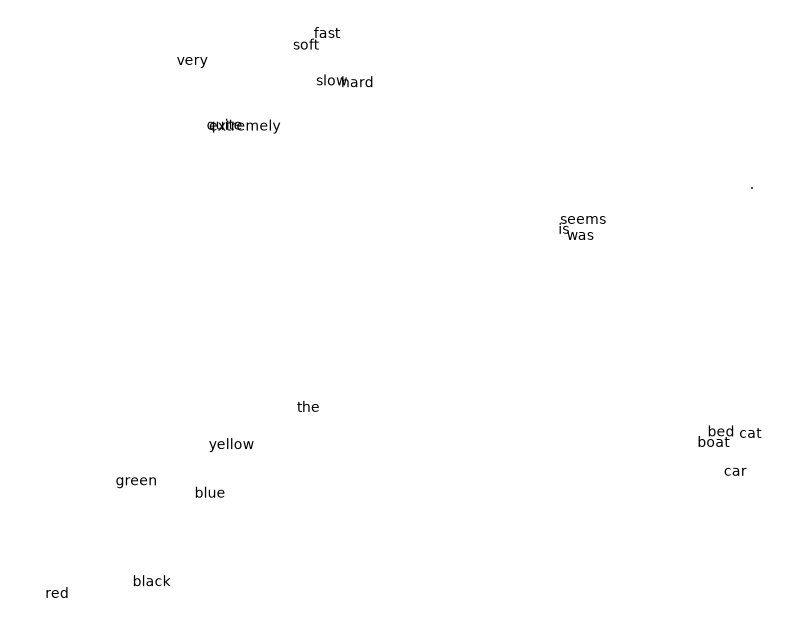

In [27]:
import numpy as np

# Centrowanie danych wokół średniej
X = np.array(embedding.embeddings)
X_centered = X - np.mean(X, axis=0)

# SVD: X_centered = U * S * Vt
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

# Rzut na 2 pierwsze składowe główne (odpowiednik transformed)
transformed = X_centered @ Vt[:2].T

import matplotlib.pyplot as plt

# 1. Konwersja wektorów na macierz NumPy (jeśli są listą list lub własnym typem Tensor)
embeddings_matrix = np.array(embedding.embeddings)

# 3. Wykres punktowy (indeksowanie wycinkami NumPy zamiast *zip(*transformed))
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(transformed[:, 0], transformed[:, 1], marker='.', color='w')

# 4. Naniesienie etykiet tekstowych
for word, idx in vocab.w2i.items():
    ax.annotate(word, (transformed[idx, 0], transformed[idx, 1]))

# 5. Wbudowane, czyste ukrycie obu osi na raz
ax.axis('off')
plt.show()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ word_embedding (Embedding)      │ (None, 10)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 22)             │           242 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 462 (1.80 KB)

 Trainable params: 462 (1.80 KB)

 Non-trainable params: 0 (0.00 B)

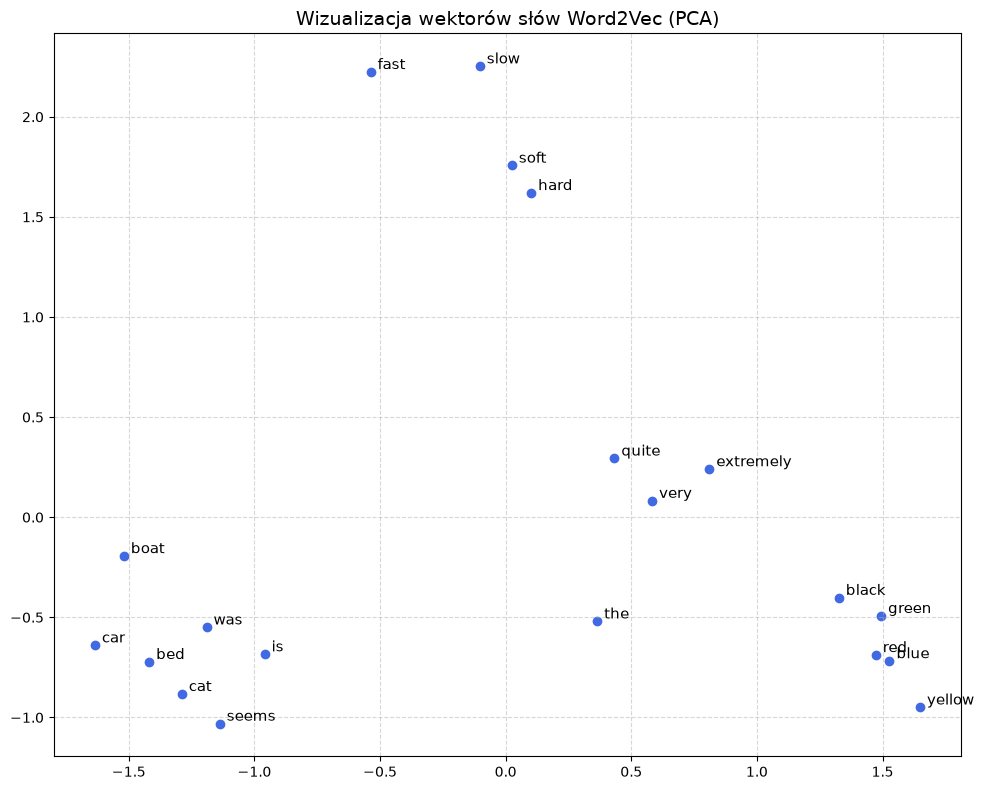

In [28]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
import tensorflow as tf

max_tokens = 5000
embedding_dim = 10  # wymiar wektora słowa

vectorize_layer = tf.keras.layers.TextVectorization(
    max_tokens=max_tokens,
    output_mode="int",
    standardize="lower_and_strip_punctuation",
    split="whitespace",
)


vectorize_layer.adapt(sentences)
vocab = vectorize_layer.get_vocabulary()
vocab_size = len(vocab)


sequences = vectorize_layer(sentences).numpy()


window_size = 2  # szerokość okna kontekstu w lewo i prawo
pairs = []

for seq in sequences:
    # Odrzucamy tokeny paddingu (indeks 0) i słowa nieznane (indeks 1)
    clean_seq = [token for token in seq if token > 1]
    n = len(clean_seq)

    for i, target_word in enumerate(clean_seq):
        start = max(0, i - window_size)
        end = min(n, i + window_size + 1)
        for j in range(start, end):
            if i != j:
                pairs.append((target_word, clean_seq[j]))

pairs = np.array(pairs)
x_train = pairs[:, 0]  # słowa wejściowe (target)
y_train = pairs[:, 1]  # słowa kontekstowe do przewidzenia (context)

model = tf.keras.Sequential([
    # Warstwa wejściowa przyjmuje pojedynczy indeks (skalar)
    tf.keras.layers.Input(shape=()),
    # Warstwa osadzeń – lookup table o wymiarach (vocab_size x embedding_dim)
    tf.keras.layers.Embedding(
        input_dim=vocab_size, output_dim=embedding_dim, name="word_embedding"
    ),
    # Rzutowanie na cały słownik + Softmax (predykcja słowa z otoczenia)
    tf.keras.layers.Dense(units=vocab_size, activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

model.summary()

# Trenowanie modelu
model.fit(x_train, y_train, epochs=200, batch_size=32, verbose=0)


embedding_layer = model.get_layer("word_embedding")
embeddings_matrix = (
    embedding_layer.get_weights()[0]
)  # macierz (vocab_size, embedding_dim)


words_to_plot = vocab[2:]
vectors_to_plot = embeddings_matrix[2:]

# Redukcja wymiarowości do 2 składowych
pca = PCA(n_components=2)
transformed = pca.fit_transform(vectors_to_plot)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(transformed[:, 0], transformed[:, 1], marker="o", color="royalblue")

# Podpisanie każdego punktu odpowiednim słowem
for i, word in enumerate(words_to_plot):
    ax.annotate(
        word,
        (transformed[i, 0], transformed[i, 1]),
        fontsize=11,
        xytext=(5, 2),
        textcoords="offset points",
    )

ax.grid(True, linestyle="--", alpha=0.5)
ax.set_title("Wizualizacja wektorów słów Word2Vec (PCA)", fontsize=14)

plt.tight_layout()
plt.show()

Kształt wektora y: (22,)
Suma prawdopodobieństw: 0.9999999
the


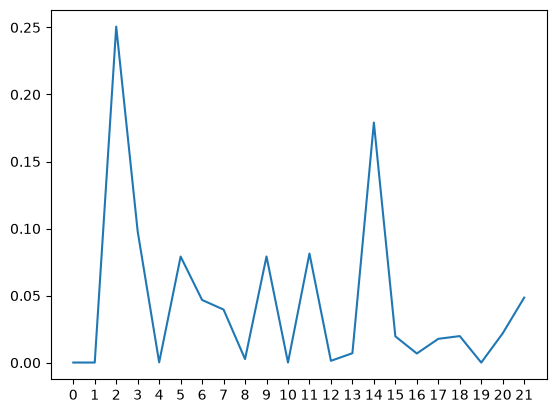

In [29]:
word = "cat"

word_idx = vocab.index(word)
y_probs = model.predict(np.array([word_idx]), verbose=0)[0]

print("Kształt wektora y:", y_probs.shape)
plt.plot(y_probs)
plt.xticks(np.arange(0,len(y_probs), 1))
print("Suma prawdopodobieństw:", np.sum(y_probs))
print(vocab[np.argmax(y_probs)])

In [ ]:
# recurrent neural networks

def dot(v: List[float], w: List[float]) -> float:
    """Oblicza iloczyn skalarny dwóch wektorów: v_1 * w_1 + ... + v_n * w_n."""
    assert len(v) == len(w), "Wektory muszą mieć tę samą długość"
    return sum(v_i * w_i for v_i, w_i in zip(v, w))


def tanh(x: float) -> float:
    
    return math.tanh(x)

class SimpleRnn(Layer):
    """Just about the simplest possible recurrent layer."""
    def __init__(self, input_dim: int, hidden_dim: int) -> None:
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim

        self.w = random_tensor(hidden_dim, input_dim, init='xavier')
        self.u = random_tensor(hidden_dim, hidden_dim, init='xavier')
        self.b = random_tensor(hidden_dim)

        self.reset_hidden_state()

    def reset_hidden_state(self) -> None:
        self.hidden = [0 for _ in range(self.hidden_dim)]

    def forward(self, input: Tensor) -> Tensor:
        self.input = input              # Save both input and previous
        self.prev_hidden = self.hidden  # hidden state to use in backprop.

        a = [(dot(self.w[h], input) +           # weights @ input
              dot(self.u[h], self.hidden) +     # weights @ hidden
              self.b[h])                        # bias
             for h in range(self.hidden_dim)]

        self.hidden = tensor_apply(tanh, a)  # Apply tanh activation
        return self.hidden                   # and return the result.

    def backward(self, gradient: Tensor):
        # Backpropagate through the tanh
        a_grad = [gradient[h] * (1 - self.hidden[h] ** 2)
                  for h in range(self.hidden_dim)]

        # b has the same gradient as a
        self.b_grad = a_grad

        # Each w[h][i] is multiplied by input[i] and added to a[h],
        # so each w_grad[h][i] = a_grad[h] * input[i]
        self.w_grad = [[a_grad[h] * self.input[i]
                        for i in range(self.input_dim)]
                       for h in range(self.hidden_dim)]

        # Each u[h][h2] is multiplied by hidden[h2] and added to a[h],
        # so each u_grad[h][h2] = a_grad[h] * prev_hidden[h2]
        self.u_grad = [[a_grad[h] * self.prev_hidden[h2]
                        for h2 in range(self.hidden_dim)]
                       for h in range(self.hidden_dim)]

        # Each input[i] is multiplied by every w[h][i] and added to a[h],
        # so each input_grad[i] = sum(a_grad[h] * w[h][i] for h in ...)
        return [sum(a_grad[h] * self.w[h][i] for h in range(self.hidden_dim))
                for i in range(self.input_dim)]

    def params(self) -> Iterable[Tensor]:
        return [self.w, self.u, self.b]

    def grads(self) -> Iterable[Tensor]:
        return [self.w_grad, self.u_grad, self.b_grad]
        

In [37]:
import requests

url = "https://45bwzj1sgc-dsn.algolia.net/1/indexes/*/queries"
params = {
    "x-algolia-agent": "Algolia for JavaScript",
    "x-algolia-application-id": "45BWZJ1SGC",
    "x-algolia-api-key": "ZmE0Y2VlZDg4OGUzODJhN2Q5YWU1OWY5MDk2MWVhNjE0YjI1MTQ4NDBhZDJjYjNhM2M4MmU0ZjQ4Y2FhOWEzMWFuYWx5dGljc1RhZ3M9eWNkYyZyZXN0cmljdEluZGljZXM9WUNDb21wYW55X3Byb2R1Y3Rpb24lMkNZQ0NvbXBhbnlfQnlfTGF1bmNoX0RhdGVfcHJvZHVjdGlvbiZ0YWdGaWx0ZXJzPSU1QiUyMnljZGNfcHVibGljJTIyJTVEJnZhbGlkVW50aWw9MTc5MTgyNzE3OQ=="
}

payload = {
    "requests": [
        {
            "indexName": "YCCompany_production",
            "params": "hitsPerPage=100&page=0"
        }
    ]
}

response = requests.post(url, params=params, json=payload)
data = response.json()

companies = [hit["name"] for hit in data["results"][0]["hits"]]
print(companies[:10])
assert len(companies) == 100


['DoorDash', 'Airbnb', 'Coinbase', 'Groww', 'Instacart', 'Meesho', 'GitLab', 'Oklo', 'Dropbox', 'Rigetti Computing']


In [51]:
companies = [
    # 1 - 20 (Najwięksi giganci: paliwa, retail, energetyka, surowce, motoryzacja)
    "Orlen",
    "Jeronimo Martins Polska (Biedronka)",
    "PGE (Polska Grupa Energetyczna)",
    "Totalizator Sportowy",
    "KGHM Polska Miedź",
    "Tauron Polska Energia",
    "Enea",
    "Lidl Polska",
    "Eurocash",
    "Polskie Sieci Elektroenergetyczne (PSE)",
    "Dino Polska",
    "Grupa Żabka",
    "Volkswagen Poznań",
    "Volkswagen Group Polska",
    "ArcelorMittal Poland",
    "LPP (Reserved, Sinsay, Cropp)",
    "Toyota Central Europe",
    "BP Europa SE (Oddział w Polsce)",
    "Inter Cars",
    "Rossmann SDP",

    # 21 - 40 (Telekomunikacja, IT, bankowość, ubezpieczenia, handel)
    "Orange Polska",
    "PKO Bank Polski",
    "Grupa Polsat Plus (Cyfrowy Polsat)",
    "Pekao SA",
    "Grupa P4 (Play)",
    "Grupa PZU",
    "Santander Bank Polska",
    "Asseco Poland",
    "Allegro",
    "Auchan Polska",
    "Kaufland Polska",
    "Carrefour Polska",
    "Castorama Polska",
    "TERG (Media Expert)",
    "Grupa Muszkieterów (Intermarché / Bricomarché)",
    "Pelion (DOZ)",
    "Neuca",
    "AB SA",
    "Samsung Electronics Polska",
    "LG Energy Solution Wrocław",

    # 41 - 60 (Przemysł, logistyka, chemia, finanse, motoryzacja)
    "Stellantis Gliwice",
    "Budimex",
    "Grupa Azoty",
    "JSW (Jastrzębska Spółka Węglowa)",
    "Polska Grupa Górnicza (PGG)",
    "PKP Cargo",
    "Grupa Maspex",
    "Animex Foods",
    "Mlekovita",
    "Mlekpol",
    "Philip Morris Polska",
    "British American Tobacco Polska",
    "mBank",
    "ING Bank Śląski",
    "BNP Paribas Bank Polska",
    "Grupa Canpack",
    "Ciech",
    "Alior Bank",
    "Grupa Boryszew",
    "Synthos",

    # 61 - 80 (Elektronika, FMCG, farmacja, transport, budownictwo)
    "Mercedes-Benz Manufacturing Poland",
    "Volvo Polska",
    "ZF Automotive Systems Poland",
    "Grupa CCC (CCC, HalfPrice, eobuwie)",
    "T-Mobile Polska",
    "InPost",
    "DPD Polska",
    "Poczta Polska",
    "Polimex Mostostal",
    "Strabag Polska",
    "Skanska Polska",
    "Erbud",
    "Grupa Kęty",
    "Celsa Huta Ostrowiec",
    "Amrest (KFC, Pizza Hut, Burger King)",
    "Tchibo Warszawa",
    "Żywiec Zdrój",
    "Grupa Żywiec",
    "Kompania Piwowarska",
    "Carlsberg Polska",

    # 81 - 100 (Pozostałe wiodące podmioty produkcyjne, dystrybucyjne i handlowe)
    "Farmacol",
    "Polska Grupa Farmaceutyczna (PGF)",
    "Adamed Pharma",
    "Polpharma",
    "Fiege",
    "Raben Group",
    "H&M Hennes & Mauritz Polska",
    "Pepco Poland",
    "Leroy Merlin Polska",
    "IKEA Retail Polska",
    "Decathlon Polska",
    "Action Poland",
    "Grupa Kronospan",
    "Mondi Świecie",
    "Stora Enso Poland",
    "Cemex Polska",
    "Górczewska (Grupa Mokate)",
    "Colian",
    "Tele-Fonika Kable",
    "Comarch"
]

vocab = Vocabulary([c for company in companies for c in company])

START = "^"
STOP = "$"

# We need to add them to the vocabulary too.
vocab.add(START)
vocab.add(STOP)

HIDDEN_DIM = 32 

rnn1 =  SimpleRnn(input_dim=vocab.size, hidden_dim=HIDDEN_DIM)
rnn2 =  SimpleRnn(input_dim=HIDDEN_DIM, hidden_dim=HIDDEN_DIM)
linear = Linear(input_dim=HIDDEN_DIM, output_dim=vocab.size)

model = Sequential([
    rnn1,
    rnn2,
    linear
])

In [53]:
def generate(seed: str = START, max_len: int = 50) -> str:
    rnn1.reset_hidden_state()  # Reset both hidden states.
    rnn2.reset_hidden_state()
    output = [seed]            # Start the output with the specified seed.

    # Keep going until we produce the STOP character or reach the max length
    while output[-1] != STOP and len(output) < max_len:
        # Use the last character as the input
        input = vocab.one_hot_encode(output[-1])

        # Generate scores using the model
        predicted = model.forward(input)

        # Convert them to probabilities and draw a random char_id
        probabilities = softmax(predicted)
        next_char_id = sample_from(probabilities)

        # Add the corresponding char to our output
        output.append(vocab.get_word(next_char_id))

    # Get rid of START and END characters and return the word.
    return ''.join(output[1:-1])

loss = SoftmaxCrossEntropy()
optimizer = Momentum(learning_rate=0.01, momentum=0.9)

for epoch in range(300):
    random.shuffle(companies)  # Train in a different order each epoch.
    epoch_loss = 0             # Track the loss.
    for company in tqdm.tqdm(companies):
        rnn1.reset_hidden_state()  # Reset both hidden states.
        rnn2.reset_hidden_state()
        company = START + company + STOP   # Add START and STOP characters.

        # The rest is just our usual training loop, except that the inputs
        # and target are the one-hot-encoded previous and next characters.
        for prev, next in zip(company, company[1:]):
            input = vocab.one_hot_encode(prev)
            target = vocab.one_hot_encode(next)
            predicted = model.forward(input)
            epoch_loss += loss.loss(predicted, target)
            gradient = loss.gradient(predicted, target)
            model.backward(gradient)
            optimizer.step(model)

    # Each epoch print the loss and also generate a name
    print(epoch, epoch_loss, generate())

    # Turn down the learning rate for the last 100 epochs.
    # There's no principled reason for this, but it seems to work.
    if epoch == 200:
        optimizer.lr *= 0.1

100%|██████████| 100/100 [00:02<00:00, 34.67it/s]


0 2404.669792110411 OEHka


100%|██████████| 100/100 [00:02<00:00, 35.06it/s]


1 2367.4891231985644 Grupa Kętoliba Mie- Gns Mosporbsblann (PGR)


100%|██████████| 100/100 [00:02<00:00, 34.98it/s]


...

297 974.0857162052511 Stora Polsat)


100%|██████████| 100/100 [00:02<00:00, 35.33it/s]


298 975.2265806344433 Stell Polska


100%|██████████| 100/100 [00:02<00:00, 35.30it/s]

299 975.7918410708656 Amrestycine)
